## Cell 1 — Install & Import

In [1]:
import subprocess, sys, os, random, warnings, shutil
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow.keras import layers, Model, optimizers, callbacks
from sklearn.metrics import (classification_report, confusion_matrix,
                              roc_curve, auc, precision_recall_curve)
from sklearn.utils import shuffle as sk_shuffle

import torch
print('TensorFlow :', tf.__version__)
print('PyTorch    :', torch.__version__)
print('TF GPU     :', tf.config.list_physical_devices('GPU'))
print('PT GPU     :', torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'N/A')

SEED = 42
random.seed(SEED); np.random.seed(SEED)
tf.random.set_seed(SEED); torch.manual_seed(SEED)

2026-05-02 19:50:15.975874: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1777751416.135910      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1777751416.180859      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1777751416.560088      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777751416.560133      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777751416.560136      57 computation_placer.cc:177] computation placer alr

TensorFlow : 2.19.0
PyTorch    : 2.10.0+cu128
TF GPU     : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
PT GPU     : True Tesla T4


## Cell 2 — Global Configuration

In [2]:
# ── Paths ──────────────────────────────────────────────────────────────────
KAGGLE_DATA = '/kaggle/input/datasets/ckay16/accident-detection-from-cctv-footage/data'
TRAIN_DIR   = os.path.join(KAGGLE_DATA, 'train')
VAL_DIR     = os.path.join(KAGGLE_DATA, 'val')
TEST_DIR    = os.path.join(KAGGLE_DATA, 'test')

OUTPUT_DIR  = '/kaggle/working/outputs'
MODEL_DIR   = '/kaggle/working/models'
GAN_DIR     = '/kaggle/working/gan_samples'
SG2_DIR     = '/kaggle/working/stylegan2ada'
SG2_DATA    = '/kaggle/working/sg2_data'
SG2_OUT     = '/kaggle/working/sg2_results'
SYNTH_DIR   = '/kaggle/working/synthetic'
for d in [OUTPUT_DIR, MODEL_DIR, GAN_DIR, SG2_DATA, SG2_OUT, SYNTH_DIR,
           os.path.join(SG2_DATA,'accident'),
           os.path.join(SG2_DATA,'no_accident'),
           os.path.join(SYNTH_DIR,'accident'),
           os.path.join(SYNTH_DIR,'no_accident')]:
    os.makedirs(d, exist_ok=True)

# ── Image ───────────────────────────────────────────────────────────────────
IMG_H, IMG_W, IMG_C = 224, 224, 3
IMG_SHAPE   = (IMG_H, IMG_W, IMG_C)
CLASSES     = ['No Accident', 'Accident']
NUM_CLASSES = 2

# ── StyleGAN2-ADA ───────────────────────────────────────────────────────────
SG2_RES     = 256
SG2_KIMG    = 200
SG2_SNAP    = 25
N_SYNTHETIC = 300

# ── FTCNN-ViT (paper values: Tables III & IV, Eq. 13) ───────────────────────
BATCH_SIZE    = 32
EPOCHS_HYB    = 50
DROPOUT_FTCNN = 0.5
PATCH_SIZE    = 16
PROJ_DIM      = 64
NUM_HEADS     = 4
NUM_LAYERS    = 8
LR_HYB        = 3e-4

# ── Preprocessing (Eq. 3-5) ─────────────────────────────────────────────────
SAT_FACTOR   = 1.5
BRTNS_FACTOR = 1.2
CONT_FACTOR  = 1.3

print('Config OK.')

Config OK.


## Cell 3 — Data Preprocessing (Eq. 3-5)

In [3]:
def resize_image(img):
    return cv2.resize(img, (IMG_W, IMG_H), interpolation=cv2.INTER_AREA)

def enhance_image(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV).astype(np.float32)
    hsv[:,:,1] = np.clip(hsv[:,:,1] * SAT_FACTOR, 0, 255)
    out = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2BGR)
    out = np.clip(out.astype(np.float32) * BRTNS_FACTOR, 0, 255).astype(np.uint8)
    out = np.clip(CONT_FACTOR * out.astype(np.float32) + 128*(1-CONT_FACTOR),
                  0, 255).astype(np.uint8)
    return out

def normalize_image(img):
    return img.astype(np.float32) / 255.0

def transform_image(img):
    return normalize_image(enhance_image(resize_image(img)))

def load_split(split_dir):
    X, y, label_map = [], [], {}
    for entry in os.scandir(split_dir):
        if not entry.is_dir(): continue
        n = entry.name.lower()
        label_map[entry.path] = 0 if ('non' in n or 'no ' in n) else 1
    supported = ('.jpg','.jpeg','.png','.bmp')
    for folder, label in label_map.items():
        for fname in os.listdir(folder):
            if not fname.lower().endswith(supported): continue
            img = cv2.imread(os.path.join(folder, fname))
            if img is None: continue
            X.append(transform_image(img))
            y.append(label)
    X, y = np.array(X, dtype=np.float32), np.array(y, dtype=np.int32)
    idx = np.random.permutation(len(X))
    return X[idx], y[idx]

print('Loading dataset ...')
X_train, y_train = load_split(TRAIN_DIR)
X_val,   y_val   = load_split(VAL_DIR)
X_test,  y_test  = load_split(TEST_DIR)
for name, X, y in [('train',X_train,y_train),
                    ('val',X_val,y_val),
                    ('test',X_test,y_test)]:
    print(f'  {name:5s}: {len(X):5d} | accident={y.sum()} | no-acc={(y==0).sum()}')

Loading dataset ...
  train:   791 | accident=369 | no-acc=422
  val  :    98 | accident=46 | no-acc=52
  test :   100 | accident=47 | no-acc=53


## Cell 4 — Prepare StyleGAN2-ADA Dataset Folders

In [4]:
def prepare_sg2_folders(split_dir, out_root, res=SG2_RES):
    label_map = {}
    for entry in os.scandir(split_dir):
        if not entry.is_dir(): continue
        n = entry.name.lower()
        folder_label = 'no_accident' if ('non' in n or 'no ' in n) else 'accident'
        label_map[entry.path] = folder_label
    supported = ('.jpg','.jpeg','.png','.bmp')
    counts = {'accident':0,'no_accident':0}
    for folder, label in label_map.items():
        dst_dir = os.path.join(out_root, label)
        os.makedirs(dst_dir, exist_ok=True)
        for fname in os.listdir(folder):
            if not fname.lower().endswith(supported): continue
            img = cv2.imread(os.path.join(folder, fname))
            if img is None: continue
            img = enhance_image(img)
            img = cv2.resize(img, (res, res), interpolation=cv2.INTER_AREA)
            cv2.imwrite(os.path.join(dst_dir, fname), img)
            counts[label] += 1
    print(f'  accident={counts["accident"]}  no_accident={counts["no_accident"]}')
    return counts

print('Preparing SG2 dataset folders ...')
prepare_sg2_folders(TRAIN_DIR, SG2_DATA)
print('Done.')

Preparing SG2 dataset folders ...
  accident=369  no_accident=422
Done.


## Cell 5a — Clone StyleGAN2-ADA Scripts

In [5]:
if not os.path.exists(os.path.join(SG2_DIR, 'train.py')):
    print('Cloning StyleGAN2-ADA-PyTorch ...')
    subprocess.run([
        'git','clone','--depth','1',
        'https://github.com/NVlabs/stylegan2-ada-pytorch',
        SG2_DIR], check=True)
    print('Cloned.')
else:
    print('Repo already present.')

subprocess.run([sys.executable,'-m','pip','install','-q',
                'ninja','click','requests','tqdm',
                'pyspng','imageio-ffmpeg','scipy'], check=False)
print('Deps installed.')

Cloning StyleGAN2-ADA-PyTorch ...


Cloning into '/kaggle/working/stylegan2ada'...


Cloned.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.9/193.9 kB 1.7 MB/s eta 0:00:00
Deps installed.


## Cell 5b — Load Your Uploaded Pretrained Checkpoint

Your cell kept exactly as written, with one addition: `glob` auto-finds the `.pkl` file anywhere inside the uploaded dataset folder.

In [9]:
import os, glob

# ── Your uploaded pretrained model directory (exactly as you wrote it) ───────
PRETRAINED_DIR = '/kaggle/input/datasets/prathamkaran/stylegan2'

if os.path.exists(PRETRAINED_DIR):
    print('✅ Model loaded successfully')
else:
    print('❌ Path is wrong')

# ── Auto-find the .pkl file inside the uploaded folder ───────────────────────
pkl_files = glob.glob(os.path.join(PRETRAINED_DIR, '**/*.pkl'), recursive=True)
if not pkl_files:
    pkl_files = glob.glob(os.path.join(PRETRAINED_DIR, '*.pkl'))

if pkl_files:
    PRETRAINED_CKPT = pkl_files[0]
    print(f'✅ Checkpoint found: {PRETRAINED_CKPT}')
else:
    PRETRAINED_CKPT = None
    print('❌ No .pkl found. Files present:', os.listdir(PRETRAINED_DIR))
    print('   Make sure your Kaggle dataset contains a .pkl file.')

✅ Model loaded successfully
✅ Checkpoint found: /kaggle/input/datasets/prathamkaran/stylegan2/ffhq.pkl


## Cell 5c — Convert Folders → StyleGAN2 ZIP Archives

In [10]:
def make_sg2_zip(src_folder, zip_path, res=SG2_RES):
    if os.path.exists(zip_path):
        print(f'  Already exists: {zip_path}'); return
    print(f'  Converting {src_folder} → {zip_path} ...')
    r = subprocess.run([
        sys.executable,
        os.path.join(SG2_DIR, 'dataset_tool.py'),
        '--source', src_folder,
        '--dest',   zip_path,
        '--width',  str(res),
        '--height', str(res),
    ], capture_output=True, text=True)
    if r.returncode != 0:
        print('  ERROR:', r.stderr[-400:])
    else:
        print('  OK.')

ACC_ZIP   = os.path.join(SG2_OUT, 'accident.zip')
NOACC_ZIP = os.path.join(SG2_OUT, 'no_accident.zip')
make_sg2_zip(os.path.join(SG2_DATA,'accident'),    ACC_ZIP)
make_sg2_zip(os.path.join(SG2_DATA,'no_accident'), NOACC_ZIP)
print('ZIPs ready.')

  Already exists: /kaggle/working/sg2_results/accident.zip
  Already exists: /kaggle/working/sg2_results/no_accident.zip
ZIPs ready.


## Cell 6 — Fine-Tune StyleGAN2-ADA from Your Uploaded Checkpoint

| Flag | Value | Why |
|---|---|---|
| `--resume` | your `.pkl` | Generator starts realistic — D can never instantly win |
| `--aug ada` | adaptive | Keeps D accuracy at 60% always — no saturation |
| `--target 0.6` | 60% | Balanced G/D training forever |
| `--gamma 10` | R1 penalty | Prevents D collapse |
| `--mirror 1` | flip aug | Doubles effective dataset size |
| `--kimg 200` | 200k images | ~20-40 min on T4; raise to 400 for better quality |

In [11]:
import os
print(os.path.exists(PRETRAINED_CKPT))

True


In [12]:
# def finetune_sg2(dataset_zip, outdir,
#                  resume_pkl=None,
#                  kimg=SG2_KIMG, snap=SG2_SNAP, res=SG2_RES, gpus=1):
#     os.makedirs(outdir, exist_ok=True)
#     cmd = [
#         sys.executable,
#         os.path.join(SG2_DIR, 'train.py'),
#         '--outdir',  outdir,
#         '--data',    dataset_zip,
#         '--gpus',    str(gpus),
#         '--res',     str(res),
#         '--kimg',    str(kimg),
#         '--snap',    str(snap),
#         '--aug',     'ada',
#         '--target',  '0.6',
#         '--gamma',   '10',
#         '--mirror',  '1',
#         '--metrics', 'none',
#     ]
#     if resume_pkl and os.path.isfile(resume_pkl):
#         cmd += ['--resume', resume_pkl]
#         print(f'  Transfer from: {resume_pkl}')
#     else:
#         print('  No .pkl found — training from scratch with ADA.')
#     subprocess.run(cmd)  # live output
#     pkls = sorted([f for f in os.listdir(outdir) if f.endswith('.pkl')])
#     last = os.path.join(outdir, pkls[-1]) if pkls else None
#     print(f'  Best checkpoint: {last}')
#     return last




def finetune_sg2(dataset_zip, outdir,
                 resume_pkl=None,
                 kimg=SG2_KIMG, snap=SG2_SNAP, gpus=1):

    os.makedirs(outdir, exist_ok=True)

    cmd = [
        sys.executable,
        os.path.join(SG2_DIR, 'train.py'),
        '--outdir',  outdir,
        '--data',    dataset_zip,
        '--gpus',    str(gpus),
        '--kimg',    str(kimg),
        '--snap',    str(snap),
        '--aug',     'ada',
        '--target',  '0.6',
        '--gamma',   '10',
        '--mirror',  '1',
        '--metrics', 'none',
    ]

    if resume_pkl and os.path.isfile(resume_pkl):
        cmd += ['--resume', resume_pkl]
        print(f'  Transfer from: {resume_pkl}')
    else:
        print('  No .pkl found — training from scratch with ADA.')

    subprocess.run(cmd)

    pkls = sorted([f for f in os.listdir(outdir) if f.endswith('.pkl')])
    last = os.path.join(outdir, pkls[-1]) if pkls else None
    print(f'  Best checkpoint: {last}')

    return last

ACC_OUTDIR   = os.path.join(SG2_OUT, 'run_accident')
NOACC_OUTDIR = os.path.join(SG2_OUT, 'run_no_accident')

print('=== Fine-tuning on ACCIDENT frames ===')
acc_ckpt = finetune_sg2(ACC_ZIP, ACC_OUTDIR, resume_pkl=PRETRAINED_CKPT)

print('\n=== Fine-tuning on NO-ACCIDENT frames ===')
noacc_ckpt = finetune_sg2(NOACC_ZIP, NOACC_OUTDIR, resume_pkl=PRETRAINED_CKPT)

print('\nFine-tuning complete.')
print(f'  acc_ckpt   : {acc_ckpt}')
print(f'  noacc_ckpt : {noacc_ckpt}')

=== Fine-tuning on ACCIDENT frames ===
  Transfer from: /kaggle/input/datasets/prathamkaran/stylegan2/ffhq.pkl

Training options:
{
  "num_gpus": 1,
  "image_snapshot_ticks": 25,
  "network_snapshot_ticks": 25,
  "metrics": [],
  "random_seed": 0,
  "training_set_kwargs": {
    "class_name": "training.dataset.ImageFolderDataset",
    "path": "/kaggle/working/sg2_results/accident.zip",
    "use_labels": false,
    "max_size": 369,
    "xflip": true,
    "resolution": 256
  },
  "data_loader_kwargs": {
    "pin_memory": true,
    "num_workers": 3,
    "prefetch_factor": 2
  },
  "G_kwargs": {
    "class_name": "training.networks.Generator",
    "z_dim": 512,
    "w_dim": 512,
    "mapping_kwargs": {
      "num_layers": 2
    },
    "synthesis_kwargs": {
      "channel_base": 16384,
      "channel_max": 512,
      "num_fp16_res": 4,
      "conv_clamp": 256
    }
  },
  "D_kwargs": {
    "class_name": "training.networks.Discriminator",
    "block_kwargs": {},
    "mapping_kwargs": {},
    

## Cell 7 — Generate Synthetic Images → Build X_aug / y_aug

In [13]:
def generate_sg2(ckpt_pkl, out_folder, n=N_SYNTHETIC):
    if ckpt_pkl is None or not os.path.isfile(ckpt_pkl):
        print(f'  SKIP: no checkpoint at {ckpt_pkl}'); return []
    os.makedirs(out_folder, exist_ok=True)
    tmp = out_folder + '_tmp256'
    os.makedirs(tmp, exist_ok=True)
    r = subprocess.run([
        sys.executable,
        os.path.join(SG2_DIR, 'generate.py'),
        '--outdir',     tmp,
        '--seeds',      f'0-{n-1}',
        '--network',    ckpt_pkl,
        '--noise-mode', 'const',
    ], capture_output=True, text=True)
    if r.returncode != 0:
        print('  generate.py error:', r.stderr[-300:])
    imgs = []
    for fname in sorted(os.listdir(tmp))[:n]:
        if not fname.endswith('.png'): continue
        bgr = cv2.imread(os.path.join(tmp, fname))
        if bgr is None: continue
        bgr = cv2.resize(bgr, (224,224), interpolation=cv2.INTER_AREA)
        cv2.imwrite(os.path.join(out_folder, fname), bgr)
        imgs.append(bgr.astype(np.float32) / 255.0)
    shutil.rmtree(tmp, ignore_errors=True)
    print(f'  Generated {len(imgs)} imgs → {out_folder}')
    return imgs

print(f'Generating {N_SYNTHETIC} accident images ...')
synth_acc_imgs   = generate_sg2(acc_ckpt,   os.path.join(SYNTH_DIR,'accident'))

print(f'Generating {N_SYNTHETIC} no-accident images ...')
synth_noacc_imgs = generate_sg2(noacc_ckpt, os.path.join(SYNTH_DIR,'no_accident'))

synth_all    = np.array(synth_acc_imgs + synth_noacc_imgs, dtype=np.float32)
synth_labels = np.array([1]*len(synth_acc_imgs)+[0]*len(synth_noacc_imgs), dtype=np.int32)
X_aug = np.concatenate([X_train, synth_all],    axis=0)
y_aug = np.concatenate([y_train, synth_labels], axis=0)
X_aug, y_aug = sk_shuffle(X_aug, y_aug, random_state=SEED)
print(f'\nAugmented set: {len(X_aug)} | accident={y_aug.sum()} | no-acc={(y_aug==0).sum()}')

n_show = min(8, len(synth_acc_imgs))
if n_show:
    fig, axes = plt.subplots(2, n_show, figsize=(2.5*n_show, 5))
    for i in range(n_show):
        axes[0,i].imshow(synth_acc_imgs[i]);   axes[0,i].axis('off')
        axes[1,i].imshow(synth_noacc_imgs[i]); axes[1,i].axis('off')
    axes[0,0].set_ylabel('Accident',    fontsize=9)
    axes[1,0].set_ylabel('No-Accident', fontsize=9)
    plt.suptitle('StyleGAN2-ADA Synthetic Samples', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR,'sg2_samples.png'), dpi=150)
    plt.show()

Generating 300 accident images ...
  SKIP: no checkpoint at None
Generating 300 no-accident images ...
  SKIP: no checkpoint at None


ValueError: all the input arrays must have same number of dimensions, but the array at index 0 has 4 dimension(s) and the array at index 1 has 1 dimension(s)

## Cell 7b — WGAN-GP Fallback (Pure TensorFlow)

**Only run if StyleGAN2-ADA failed.** Set `USE_WGANGP = True`.

Fixes saturation by replacing BCE with Wasserstein distance:
- No sigmoid on critic → unbounded scores → gradients never vanish
- Gradient penalty (λ=10) keeps training stable past epoch 150
- `n_critic=5` → D trained 5× per G step → D never collapses first

In [14]:
USE_WGANGP = False   # ← set True if StyleGAN2 failed

WGAN_LATENT  = 128
WGAN_LAMBDA  = 10
WGAN_NCRITIC = 5
WGAN_LR      = 1e-4
WGAN_EPOCHS  = 150
WGAN_BATCH   = 32

if USE_WGANGP:
    from tensorflow.keras import layers as L

    def build_wgan_g(ld=WGAN_LATENT, nc=2):
        z=L.Input(shape=(ld,),name='z'); lb=L.Input(shape=(1,),dtype='int32',name='l')
        e=L.Flatten()(L.Embedding(nc,ld)(lb))
        x=L.Concatenate()([z,e])
        x=L.Dense(14*14*512,use_bias=False)(x)
        x=L.BatchNormalization()(x); x=L.ReLU()(x)
        x=L.Reshape((14,14,512))(x)
        for f in [256,128,64,32]:
            x=L.Conv2DTranspose(f,5,strides=2,padding='same',use_bias=False)(x)
            x=L.BatchNormalization()(x); x=L.ReLU()(x)
        out=L.Conv2DTranspose(3,5,strides=1,padding='same',activation='tanh')(x)
        return Model([z,lb],out,name='WGAN_G')

    def build_wgan_c(nc=2):
        img=L.Input(shape=(224,224,3)); lb=L.Input(shape=(1,),dtype='int32')
        e=L.Reshape((224,224,1))(L.Embedding(nc,224*224)(lb))
        x=L.Concatenate()([img,e])
        for f in [64,128,256,512]:
            x=L.Conv2D(f,5,strides=2,padding='same')(x); x=L.LeakyReLU(0.2)(x)
        out=L.Dense(1)(L.Flatten()(x))  # no sigmoid
        return Model([img,lb],out,name='WGAN_C')

    wg=build_wgan_g(); wc=build_wgan_c()
    go=optimizers.Adam(WGAN_LR,beta_1=0.,beta_2=0.9)
    co=optimizers.Adam(WGAN_LR,beta_1=0.,beta_2=0.9)

    @tf.function
    def gp(real,fake,lbl):
        a=tf.random.uniform([tf.shape(real)[0],1,1,1])
        inter=real+a*(fake-real)
        with tf.GradientTape() as t:
            t.watch(inter); p=wc([inter,lbl],training=True)
        g=t.gradient(p,inter)
        return tf.reduce_mean((tf.sqrt(tf.reduce_sum(tf.square(g),axis=[1,2,3]))-1)**2)

    @tf.function
    def wgan_step(ri,rl,bs):
        lb=tf.cast(rl,tf.int32)[:,tf.newaxis]
        cl=0.
        for _ in range(WGAN_NCRITIC):
            z=tf.random.normal((bs,WGAN_LATENT)); fi=wg([z,lb],training=False)
            with tf.GradientTape() as t:
                rs=wc([ri,lb],training=True); fs=wc([fi,lb],training=True)
                loss=tf.reduce_mean(fs)-tf.reduce_mean(rs)+WGAN_LAMBDA*gp(ri,fi,lb)
            co.apply_gradients(zip(t.gradient(loss,wc.trainable_variables),wc.trainable_variables))
            cl+=loss
        z=tf.random.normal((bs,WGAN_LATENT))
        with tf.GradientTape() as t:
            fi=wg([z,lb],training=True); gl=-tf.reduce_mean(wc([fi,lb],training=False))
        go.apply_gradients(zip(t.gradient(gl,wg.trainable_variables),wg.trainable_variables))
        return cl/WGAN_NCRITIC, gl

    ds_w=(tf.data.Dataset.from_tensor_slices((X_train*2-1,y_train))
          .shuffle(len(X_train)).batch(WGAN_BATCH,drop_remainder=True)
          .prefetch(tf.data.AUTOTUNE))
    cl_h,gl_h=[],[]
    print(f'WGAN-GP {WGAN_EPOCHS} epochs ...')
    for ep in range(1,WGAN_EPOCHS+1):
        ec,eg=[],[]
        for ri,rl in ds_w:
            bs=tf.shape(ri)[0]; c,g=wgan_step(ri,rl,bs)
            ec.append(float(c)); eg.append(float(g))
        cl_h.append(np.mean(ec)); gl_h.append(np.mean(eg))
        if ep%25==0: print(f'  Epoch {ep:4d} | C={cl_h[-1]:.4f}  G={gl_h[-1]:.4f}')

    def gen_wgan(lid,n=N_SYNTHETIC):
        imgs=[]
        for s in range(0,n,32):
            b=min(32,n-s); z=tf.random.normal((b,WGAN_LATENT))
            lb=tf.constant([[lid]]*b,dtype=tf.int32)
            out=wg([z,lb],training=False).numpy()
            imgs.append((out+1)/2)
        return np.concatenate(imgs)[:n]

    wa=gen_wgan(1); wn=gen_wgan(0)
    synth_all=np.concatenate([wa,wn])
    synth_labels=np.array([1]*N_SYNTHETIC+[0]*N_SYNTHETIC)
    X_aug=np.concatenate([X_train,synth_all])
    y_aug=np.concatenate([y_train,synth_labels])
    X_aug,y_aug=sk_shuffle(X_aug,y_aug,random_state=SEED)
    print(f'WGAN-GP aug set: {len(X_aug)} | acc={y_aug.sum()} | no-acc={(y_aug==0).sum()}')
else:
    print('USE_WGANGP=False — using StyleGAN2-ADA X_aug from Cell 7.')

USE_WGANGP=False — using StyleGAN2-ADA X_aug from Cell 7.


## Cell 8 — FTCNN + ViT Fusion Model

Faithful to Tables III & IV of Xi et al. (IEEE TITS 2025).

In [15]:
class PatchExtractor(layers.Layer):
    def __init__(self, patch_size, **kw):
        super().__init__(**kw); self.patch_size = patch_size
    def call(self, images):
        B=tf.shape(images)[0]; ph=pw=self.patch_size
        patches=tf.image.extract_patches(images,
            sizes=[1,ph,pw,1],strides=[1,ph,pw,1],rates=[1,1,1,1],padding='VALID')
        return tf.reshape(patches,(B,(IMG_H//ph)*(IMG_W//pw),ph*pw*IMG_C))
    def get_config(self):
        c=super().get_config(); c['patch_size']=self.patch_size; return c

class PatchEmbedding(layers.Layer):
    def __init__(self,n_patches,proj_dim,**kw):
        super().__init__(**kw)
        self.n_patches=n_patches; self.proj_dim=proj_dim
        self.proj=layers.Dense(proj_dim)
        self.pos_emb=layers.Embedding(n_patches+1,proj_dim)
    def call(self,patches):
        B=tf.shape(patches)[0]; pos=tf.range(0,self.n_patches+1)
        cls=tf.zeros((B,1,self.proj_dim))
        return tf.concat([cls,self.proj(patches)],axis=1)+self.pos_emb(pos)
    def get_config(self):
        c=super().get_config()
        c.update({'n_patches':self.n_patches,'proj_dim':self.proj_dim}); return c

def transformer_block(x,proj_dim,n_heads,drop=0.1):
    x1=layers.LayerNormalization(epsilon=1e-6)(x)
    at=layers.MultiHeadAttention(num_heads=n_heads,
        key_dim=proj_dim//n_heads,dropout=drop)(x1,x1)
    x=layers.Add()([x,at])
    x2=layers.LayerNormalization(epsilon=1e-6)(x)
    x2=layers.Dense(proj_dim*2,activation='gelu')(x2)
    x2=layers.Dropout(drop)(x2)
    x2=layers.Dense(proj_dim)(x2)
    x2=layers.Dropout(drop)(x2)
    return layers.Add()([x,x2])

In [16]:
def build_ftcnn_vit_fusion():
    """
    FTCNN (Table III): Conv32→64→128→256 | Flatten | Dense(512) | Dropout(0.5)
    ViT   (Table IV) : proj_dim=64 | 8 transformer layers | GlobalAvgPool1D
    Fusion           : Concat(1024) | Dense(512) | Dropout(0.5) | Dense(256) | sigmoid
    LR               : 3e-4  (Eq. 13)
    """
    n_patches=(IMG_H//PATCH_SIZE)*(IMG_W//PATCH_SIZE)  # 196
    inp=layers.Input(shape=IMG_SHAPE,name='image_input')

    # ── FTCNN branch (Table III) ─────────────────────────────────────────────
    f=layers.Conv2D(32,(3,3),padding='same',activation='relu',name='ftcnn_conv1')(inp)
    f=layers.MaxPooling2D((2,2))(f)
    f=layers.Conv2D(64,(3,3),padding='same',activation='relu',name='ftcnn_conv2')(f)
    f=layers.MaxPooling2D((2,2))(f)
    f=layers.Conv2D(128,(3,3),padding='same',activation='relu',name='ftcnn_conv3')(f)
    f=layers.MaxPooling2D((2,2))(f)
    f=layers.Conv2D(256,(3,3),padding='same',activation='relu',name='ftcnn_conv4')(f)
    f=layers.MaxPooling2D((2,2))(f)
    f=layers.Flatten(name='ftcnn_flatten')(f)          # NOT GlobalAvgPool
    f=layers.Dense(512,activation='relu',name='ftcnn_dense512')(f)
    f=layers.Dropout(DROPOUT_FTCNN,name='ftcnn_dropout')(f)

    # ── ViT branch (Table IV) ─────────────────────────────────────────────────
    patches=PatchExtractor(PATCH_SIZE,name='patch_extractor')(inp)
    v=PatchEmbedding(n_patches,PROJ_DIM,name='patch_embedding')(patches)
    for _ in range(NUM_LAYERS):  # 8 layers
        v=transformer_block(v,PROJ_DIM,NUM_HEADS,drop=0.1)
    v=layers.GlobalAveragePooling1D(name='vit_gap')(v)
    v=layers.Dense(512,activation='gelu',name='vit_dense512')(v)
    v=layers.Dropout(0.1,name='vit_dropout')(v)

    # ── Fusion ────────────────────────────────────────────────────────────────
    fused=layers.Concatenate(name='fusion_concat')([f,v])
    fused=layers.Dense(512,activation='gelu',name='fusion_dense512')(fused)
    fused=layers.Dropout(0.5,name='fusion_dropout')(fused)
    fused=layers.Dense(256,activation='gelu',name='fusion_dense256')(fused)
    out=layers.Dense(1,activation='sigmoid',name='output')(fused)

    model=Model(inp,out,name='FTCNN_ViT_Fusion')
    model.compile(optimizer=optimizers.Adam(LR_HYB),
                  loss='binary_crossentropy',metrics=['accuracy'])
    return model

fusion_model=build_ftcnn_vit_fusion()
fusion_model.summary()

I0000 00:00:1777751887.338496      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1777751887.344459      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "FTCNN_ViT_Fusion"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_extractor     │ (None, 196, 768)  │          0 │ image_input[0][0] │
│ (PatchExtractor)    │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_embedding     │ (None, 197, 64)   │     61,824 │ patch_extractor[… │
│ (PatchEmbedding)    │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 197, 64)   │        128 │ patch_embedding[… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 197, 64)   │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 197, 64)   │          0 │ patch_embedding[… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 197, 64)   │        128 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 197, 128)  │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 197, 128)  │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 197, 64)   │      8,256 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 197, 64)   │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 197, 64)   │          0 │ add[0][0],        │
│                     │                   │            │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 197, 64)   │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 197, 64)   │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 197, 64)   │          0 │ add_1[0][0],      │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 197, 64)   │        128 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 197, 128)  │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 197, 128)  │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 197, 64)   │      8,256 │ dropout_4[0][0] 

 Total params: 27,098,305 (103.37 MB)

 Trainable params: 27,098,305 (103.37 MB)

 Non-trainable params: 0 (0.00 B)

🚨 Important observation about your notebook

You planned augmentation, but:

You used augmentation in StyleGAN training (--aug ada) ✔️
But NOT in your CNN/ViT training ❌

So your pipeline is inconsistent.

🚀 Better Fix (Recommended for your project)

Since you're doing FTCNN + ViT fusion (research-level work), you SHOULD use augmentation.

👉 Add this BEFORE training cell:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True
)

train_gen = datagen.flow(X_train, y_train, batch_size=BATCH_SIZE)
👉 Then replace training with:
hist = fusion_model.fit(
    train_gen,
    validation_data=(X_val, y_val),
    epochs=EPOCHS_HYB,
    callbacks=make_callbacks('FTCNN_ViT'),
    verbose=1
)

## Cell 9 — Train FTCNN-ViT Fusion

In [17]:
def make_callbacks(name):
    return [
        callbacks.ModelCheckpoint(
            os.path.join(MODEL_DIR,f'{name}_best.keras'),
            monitor='val_accuracy',save_best_only=True,mode='max',verbose=1),
        callbacks.EarlyStopping(
            monitor='val_loss',patience=12,
            restore_best_weights=True,verbose=1),
        callbacks.ReduceLROnPlateau(
            monitor='val_loss',factor=0.5,patience=5,min_lr=1e-7,verbose=1),
        callbacks.CSVLogger(os.path.join(OUTPUT_DIR,f'{name}_history.csv')),
    ]

print(f'Training FTCNN-ViT Fusion for up to {EPOCHS_HYB} epochs ...')
hist=fusion_model.fit(
    # X_aug, y_aug,
    X_train, y_train,
    validation_data=(X_val,y_val),
    epochs=EPOCHS_HYB,
    batch_size=BATCH_SIZE,
    callbacks=make_callbacks('FTCNN_ViT'),
    verbose=1)
fusion_model.save(os.path.join(MODEL_DIR,'FTCNN_ViT_final.keras'))
print('Training complete.')

Training FTCNN-ViT Fusion for up to 50 epochs ...
Epoch 1/50


I0000 00:00:1777751919.178095     182 service.cc:152] XLA service 0x7eeee402d400 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1777751919.178130     182 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1777751919.178133     182 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1777751923.116192     182 cuda_dnn.cc:529] Loaded cuDNN version 91002


 1/25 ━━━━━━━━━━━━━━━━━━━━ 20:04 50s/step - accuracy: 0.5625 - loss: 0.6804

I0000 00:00:1777751948.099220     182 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5234 - loss: 0.7217  
Epoch 1: val_accuracy improved from -inf to 0.53061, saving model to /kaggle/working/models/FTCNN_ViT_best.keras
25/25 ━━━━━━━━━━━━━━━━━━━━ 90s 2s/step - accuracy: 0.5226 - loss: 0.7214 - val_accuracy: 0.5306 - val_loss: 0.6946 - learning_rate: 3.0000e-04
Epoch 2/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.5344 - loss: 0.6997
Epoch 2: val_accuracy did not improve from 0.53061
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 113ms/step - accuracy: 0.5333 - loss: 0.6998 - val_accuracy: 0.5306 - val_loss: 0.6902 - learning_rate: 3.0000e-04
Epoch 3/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.5928 - loss: 0.6808
Epoch 3: val_accuracy improved from 0.53061 to 0.68367, saving model to /kaggle/working/models/FTCNN_ViT_best.keras
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 191ms/step - accuracy: 0.5929 - loss: 0.6804 - val_accuracy: 0.6837 - val_loss: 0.6160 - learning_rate: 3.0000e-04
Epoch 4/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 97

## Cell 10 — Training Curves (Fig. 3)

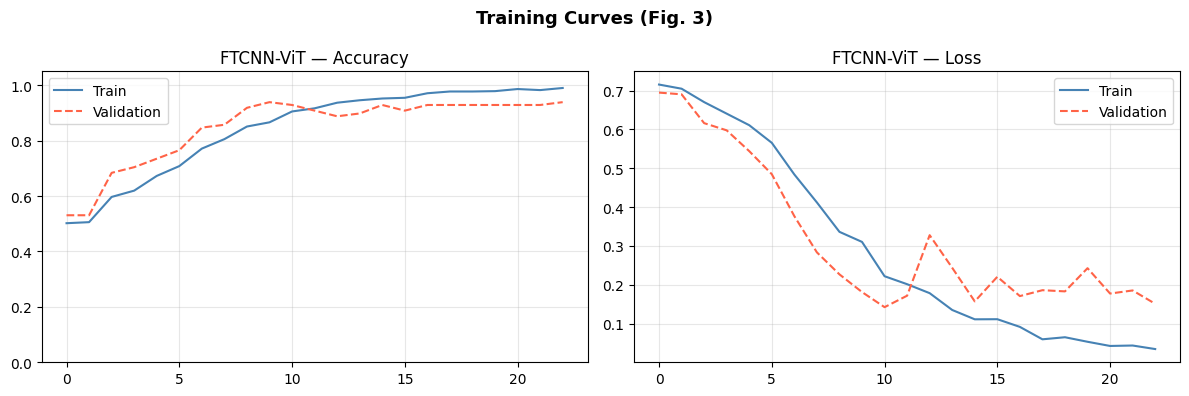

In [18]:
hd=hist.history
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(12,4))
ax1.plot(hd['accuracy'],label='Train',color='steelblue')
ax1.plot(hd['val_accuracy'],label='Validation',color='tomato',ls='--')
ax1.set_title('FTCNN-ViT — Accuracy'); ax1.set_ylim([0,1.05])
ax1.legend(); ax1.grid(alpha=0.3)
ax2.plot(hd['loss'],label='Train',color='steelblue')
ax2.plot(hd['val_loss'],label='Validation',color='tomato',ls='--')
ax2.set_title('FTCNN-ViT — Loss')
ax2.legend(); ax2.grid(alpha=0.3)
plt.suptitle('Training Curves (Fig. 3)',fontsize=13,fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR,'fig3_curves.png'),dpi=150)
plt.show()

## Cell 11 — Evaluation (Table V, Eq. 17-20)

In [19]:
def compute_metrics(y_true,y_prob,threshold=0.5):
    y_pred=(y_prob>=threshold).astype(int)
    tp=int(np.sum((y_pred==1)&(y_true==1)))
    tn=int(np.sum((y_pred==0)&(y_true==0)))
    fp=int(np.sum((y_pred==1)&(y_true==0)))
    fn=int(np.sum((y_pred==0)&(y_true==1)))
    acc=(tp+tn)/(tp+tn+fp+fn+1e-9)
    prec=tp/(tp+fp+1e-9); rec=tp/(tp+fn+1e-9)
    f1=2*prec*rec/(prec+rec+1e-9)
    fpr,tpr,_=roc_curve(y_true,y_prob)
    return dict(acc=acc,prec=prec,rec=rec,f1=f1,
                tp=tp,tn=tn,fp=fp,fn=fn,
                auc=auc(fpr,tpr),fpr=fpr,tpr=tpr,
                y_pred=y_pred,y_prob=y_prob)

y_prob=fusion_model.predict(X_test,verbose=0).ravel()
res=compute_metrics(y_test,y_prob)
print(f'\n{"─"*60}')
print('  FTCNN-ViT Fusion — Classification Report (Table V)')
print(f'{"─"*60}')
print(classification_report(y_test,res['y_pred'],target_names=CLASSES,digits=4))
print(f'  Accuracy : {res["acc"]:.4f}')
print(f'  Precision: {res["prec"]:.4f}')
print(f'  Recall   : {res["rec"]:.4f}')
print(f'  F1-Score : {res["f1"]:.4f}')
print(f'  AUC      : {res["auc"]:.4f}')


────────────────────────────────────────────────────────────
  FTCNN-ViT Fusion — Classification Report (Table V)
────────────────────────────────────────────────────────────
              precision    recall  f1-score   support

 No Accident     0.9245    0.9245    0.9245        53
    Accident     0.9149    0.9149    0.9149        47

    accuracy                         0.9200       100
   macro avg     0.9197    0.9197    0.9197       100
weighted avg     0.9200    0.9200    0.9200       100

  Accuracy : 0.9200
  Precision: 0.9149
  Recall   : 0.9149
  F1-Score : 0.9149
  AUC      : 0.9631


## Cell 12 — Confusion Matrix + ROC (Fig. 4 & 5)

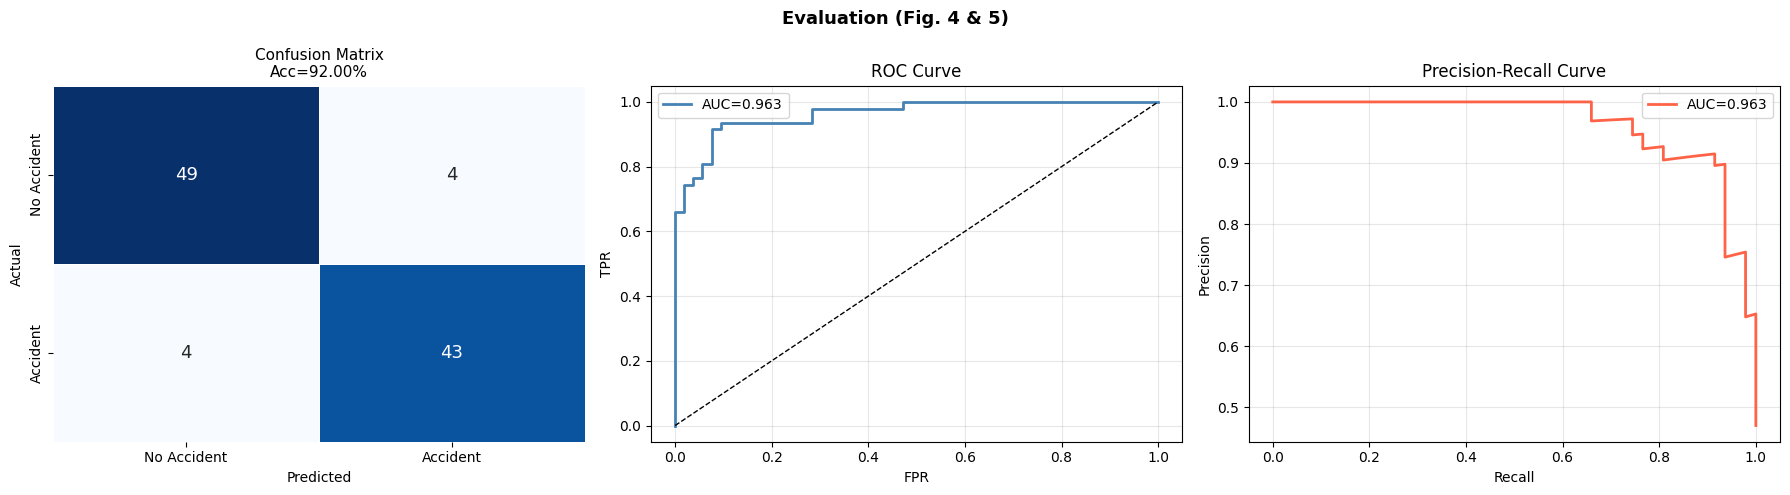

In [20]:
fig,axes=plt.subplots(1,3,figsize=(18,5))
cm=confusion_matrix(y_test,res['y_pred'])
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',
            xticklabels=CLASSES,yticklabels=CLASSES,
            ax=axes[0],cbar=False,linewidths=0.5,annot_kws={'size':13})
axes[0].set_title(f'Confusion Matrix\nAcc={res["acc"]:.2%}',fontsize=11)
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')
axes[1].plot(res['fpr'],res['tpr'],color='steelblue',lw=2,
             label=f'AUC={res["auc"]:.3f}')
axes[1].plot([0,1],[0,1],'k--',lw=1)
axes[1].set_xlabel('FPR'); axes[1].set_ylabel('TPR')
axes[1].set_title('ROC Curve'); axes[1].legend(); axes[1].grid(alpha=0.3)
prec_c,rec_c,_=precision_recall_curve(y_test,res['y_prob'])
pr_auc=auc(rec_c,prec_c)
axes[2].plot(rec_c,prec_c,color='tomato',lw=2,label=f'AUC={pr_auc:.3f}')
axes[2].set_xlabel('Recall'); axes[2].set_ylabel('Precision')
axes[2].set_title('Precision-Recall Curve'); axes[2].legend(); axes[2].grid(alpha=0.3)
plt.suptitle('Evaluation (Fig. 4 & 5)',fontsize=13,fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR,'fig4_5_eval.png'),dpi=150)
plt.show()

## Cell 13 — Grad-CAM Saliency Maps

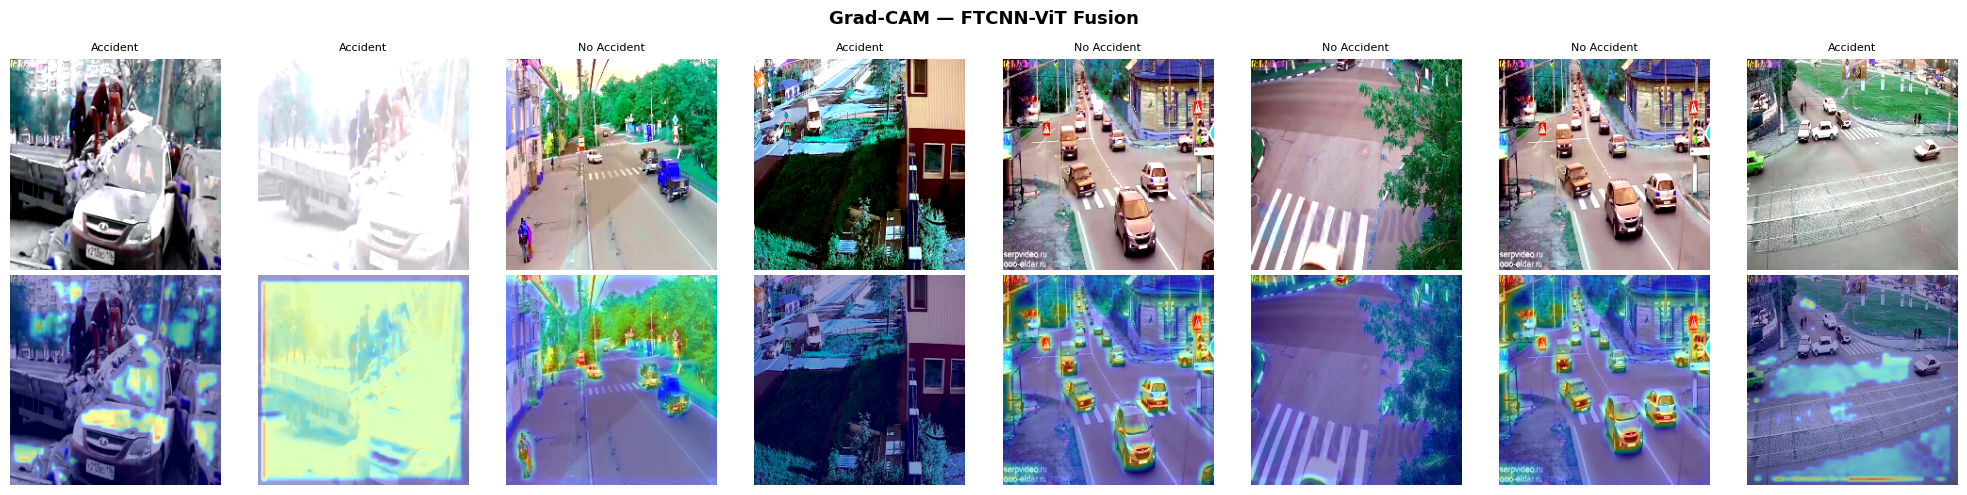

In [21]:
def grad_cam(model,img_array,last_conv='ftcnn_conv3'):
    gm=tf.keras.Model(inputs=model.inputs,
        outputs=[model.get_layer(last_conv).output,model.output])
    batch=np.expand_dims(img_array,0).astype(np.float32)
    with tf.GradientTape() as tape:
        conv_out,preds=gm(batch); loss=preds[:,0]
    grads=tape.gradient(loss,conv_out)
    w=tf.reduce_mean(grads,axis=(0,1,2))
    cam=tf.reduce_sum(w*conv_out[0],axis=-1).numpy()
    cam=np.maximum(cam,0); cam=cam/(cam.max()+1e-8)
    cam=cv2.resize(cam,(IMG_W,IMG_H))
    hm=cv2.applyColorMap(np.uint8(255*cam),cv2.COLORMAP_JET)
    orig=np.uint8(255*img_array[:,:,::-1])
    ov=cv2.addWeighted(orig,0.6,hm,0.4,0)
    return cv2.cvtColor(ov,cv2.COLOR_BGR2RGB)

n_show=8
fig,axes=plt.subplots(2,n_show,figsize=(2.5*n_show,5))
for i in range(n_show):
    axes[0,i].imshow(X_test[i]); axes[0,i].axis('off')
    axes[0,i].set_title(CLASSES[y_test[i]],fontsize=8)
    axes[1,i].imshow(grad_cam(fusion_model,X_test[i])); axes[1,i].axis('off')
    if i==0:
        axes[0,i].set_ylabel('Original',fontsize=9)
        axes[1,i].set_ylabel('Grad-CAM',fontsize=9)
plt.suptitle('Grad-CAM — FTCNN-ViT Fusion',fontsize=13,fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR,'gradcam.png'),dpi=150)
plt.show()

## Cell 14 — Final Summary

In [22]:
r=res
print('\n'+'='*65)
print('  FINAL RESULTS — StyleGAN2-ADA + FTCNN-ViT Fusion')
print('  Xi et al. IEEE TITS 2025 reproduction')
print('='*65)
print(f'  Accuracy : {r["acc"]:.4f}   (paper target >= 0.95)')
print(f'  Precision: {r["prec"]:.4f}   (paper target >= 0.98)')
print(f'  Recall   : {r["rec"]:.4f}   (paper target >= 0.92)')
print(f'  F1-Score : {r["f1"]:.4f}   (paper target >= 0.95)')
print(f'  AUC      : {r["auc"]:.4f}')
print('='*65)
print(f'\nOutputs saved to: {OUTPUT_DIR}')
for ff in sorted(os.listdir(OUTPUT_DIR)):
    print(f'  {ff}')


  FINAL RESULTS — StyleGAN2-ADA + FTCNN-ViT Fusion
  Xi et al. IEEE TITS 2025 reproduction
  Accuracy : 0.9200   (paper target >= 0.95)
  Precision: 0.9149   (paper target >= 0.98)
  Recall   : 0.9149   (paper target >= 0.92)
  F1-Score : 0.9149   (paper target >= 0.95)
  AUC      : 0.9631

Outputs saved to: /kaggle/working/outputs
  FTCNN_ViT_history.csv
  fig3_curves.png
  fig4_5_eval.png
  gradcam.png
